In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils as vutils
import matplotlib.pyplot as plt
import time


#узнать как сделать, чтобы генерировался класс по выбору.

latent_dim = 100
num_epochs = 20
batch_size = 128
learning_rate = 0.0002
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
class SimpleGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super(SimpleGenerator, self).__init__()
        self.fc = nn.Linear(latent_dim, 128 * 7 * 7)
        self.main = nn.Sequential(
            nn.BatchNorm1d(128 * 7 * 7),
            nn.Unflatten(1, (128, 7, 7)),
            
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),  # 7 - 14
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),  # 14 - 28
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            
            nn.Conv2d(32, 1, 3, 1, 1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, x):
        x = self.fc(x)
        return self.main(x)

        
class SimpleDiscriminator(nn.Module):
    def __init__(self):
        super(SimpleDiscriminator, self).__init__()
        self.main = nn.Sequential(
            # 64x14x14
            nn.Conv2d(1, 64, 3, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.25),
            
            # 128x7x7
            nn.Conv2d(64, 128, 3, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.25),
            
            # 256x4x4 (4x4)
            nn.Conv2d(128, 256, 3, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout2d(0.25),
            
            # 1x1x1
            nn.Conv2d(256, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        return self.main(x).view(-1, 1).squeeze(1)

In [3]:
# Загрузка данных
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2)

generator = SimpleGenerator(latent_dim).to(device)
discriminator = SimpleDiscriminator().to(device)

criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))

In [4]:
# Параметры
D_UPDATE_FREQ = 1  
G_UPDATE_FREQ = 2

time_start = time.time()

for epoch in range(num_epochs):
    for i, (images, _) in enumerate(dataloader):
        images = images.to(device)
        batch_size_actual = images.size(0)
        
        real_labels = torch.ones(batch_size_actual, device=device)
        fake_labels = torch.zeros(batch_size_actual, device=device)
        
        if i % (D_UPDATE_FREQ + G_UPDATE_FREQ) < D_UPDATE_FREQ:
            discriminator.zero_grad()
            
            output_real = discriminator(images)
            loss_real = criterion(output_real, real_labels)
            
            # фейковые изображения
            noise = torch.randn(batch_size_actual, latent_dim, device=device)
            fake_images = generator(noise).detach()
            output_fake = discriminator(fake_images)
            loss_fake = criterion(output_fake, fake_labels)
            
            loss_D = loss_real + loss_fake
            loss_D.backward()
            optimizer_D.step()
        
        generator.zero_grad()
        
        noise = torch.randn(batch_size_actual, latent_dim, device=device)
        fake_images = generator(noise)
        output_fake = discriminator(fake_images)
        loss_G = criterion(output_fake, real_labels)  # обман поисковика/разделителя/дискриминатора
        
        loss_G.backward()
        optimizer_G.step()
        
        if i % 100 == 0:
            # точность
            with torch.no_grad():
                output_real_eval = discriminator(images)
                pred_real = (output_real_eval > 0.5).float()
                acc_real = (pred_real == real_labels).float().mean()
                
                noise_eval = torch.randn(batch_size_actual, latent_dim, device=device)
                fake_eval = generator(noise_eval)
                output_fake_eval = discriminator(fake_eval)
                pred_fake = (output_fake_eval > 0.5).float()
                acc_fake = (pred_fake == fake_labels).float().mean()
                acc_D = (acc_real + acc_fake) / 2
                
                acc_G = (output_fake_eval > 0.5).float().mean()
            
            print(f'Epoch [{epoch+1}/{num_epochs}] Batch [{i}/{len(dataloader)}] '
                  f'Loss_G: {loss_G.item():.4f} Acc_D: {acc_D.item():.4f} Acc_G: {acc_G.item():.4f}')

#print(f"\n время: {time.time() - time_start:.2f} сек")

Epoch [1/20] Batch [0/469] Loss_G: 0.8210 Acc_D: 0.7734 Acc_G: 0.4141
Epoch [1/20] Batch [100/469] Loss_G: 0.8051 Acc_D: 0.5508 Acc_G: 0.4922
Epoch [1/20] Batch [200/469] Loss_G: 0.8187 Acc_D: 0.6055 Acc_G: 0.3750
Epoch [1/20] Batch [300/469] Loss_G: 0.9388 Acc_D: 0.7383 Acc_G: 0.1719
Epoch [1/20] Batch [400/469] Loss_G: 0.9900 Acc_D: 0.7148 Acc_G: 0.2266
Epoch [2/20] Batch [0/469] Loss_G: 1.0689 Acc_D: 0.8086 Acc_G: 0.1797
Epoch [2/20] Batch [100/469] Loss_G: 1.0859 Acc_D: 0.7344 Acc_G: 0.2734
Epoch [2/20] Batch [200/469] Loss_G: 1.0482 Acc_D: 0.6992 Acc_G: 0.2969
Epoch [2/20] Batch [300/469] Loss_G: 0.9379 Acc_D: 0.7148 Acc_G: 0.3281
Epoch [2/20] Batch [400/469] Loss_G: 1.1000 Acc_D: 0.7383 Acc_G: 0.1953
Epoch [3/20] Batch [0/469] Loss_G: 0.7915 Acc_D: 0.7188 Acc_G: 0.4219
Epoch [3/20] Batch [100/469] Loss_G: 0.9480 Acc_D: 0.6953 Acc_G: 0.2656
Epoch [3/20] Batch [200/469] Loss_G: 1.0432 Acc_D: 0.6406 Acc_G: 0.3125
Epoch [3/20] Batch [300/469] Loss_G: 1.0469 Acc_D: 0.7070 Acc_G: 0.234

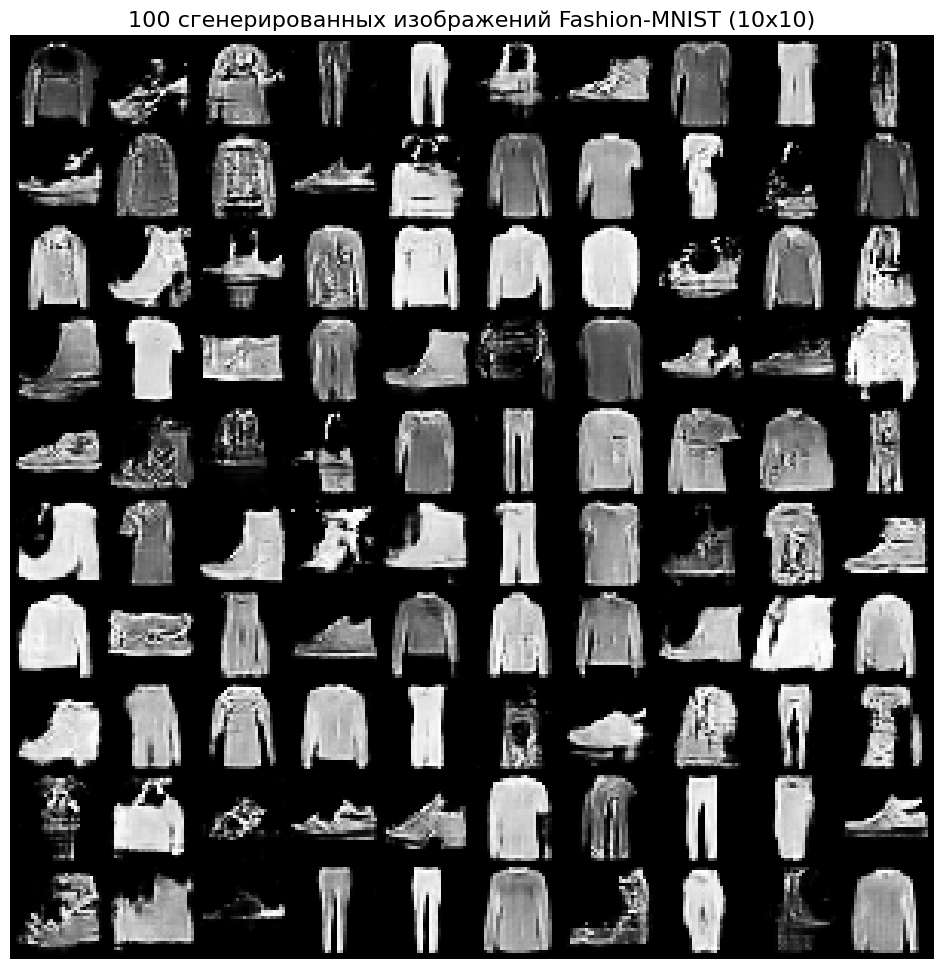

Изображения сохранены в 'generated_102.png'


In [5]:
generator.eval()
num_images = 100
batch_size_gen = 100
noise = torch.randn(batch_size_gen, latent_dim, device=device)

with torch.no_grad():
    generated_images = generator(noise)
    generated_images = (generated_images + 1) / 2


import matplotlib.pyplot as plt
from torchvision import utils as vutils

grid = vutils.make_grid(generated_images, nrow=10, padding=2, normalize=False)

plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
plt.axis('off')
plt.title('100 сгенерированных изображений Fashion-MNIST (10x10)', fontsize=16)
plt.show()

vutils.save_image(generated_images, 'generated_102.png', nrow=10, padding=2)
print("Изображения сохранены в 'generated_102.png'")